In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from RCAEval.utility import (
    read_metrics,
    read_logs,
    read_traces,
)

PROJECT_ROOT = Path.cwd().parent

manifest = pd.read_csv(
    PROJECT_ROOT
    / "data"
    / "manifests"
    / "sample_manifest.csv"
)

manifest.head()

,case,dataset,suite,system,system_name,root_cause_service,fault,fault_description,repetition,inject_time,...,duration_minutes,normal_timesteps,faulty_timesteps,has_logs,n_logs,has_traces,n_traces,has_root_cause_file,case_dir,exists
0,re2ob_checkoutservice_cpu_1,RE2-OB,RE2,ob,Online Boutique,checkoutservice,cpu,CPU stress,1,1705354566,...,24.0,720,721,True,171322,True,391997,False,/home/daniel/projects/RCAEval/data/raw/rcaeval...,True
1,re2ob_currencyservice_cpu_2,RE2-OB,RE2,ob,Online Boutique,currencyservice,cpu,CPU stress,2,1705685216,...,24.0,720,721,True,175593,True,401017,False,/home/daniel/projects/RCAEval/data/raw/rcaeval...,True
2,re2ob_emailservice_cpu_2,RE2-OB,RE2,ob,Online Boutique,emailservice,cpu,CPU stress,2,1705592998,...,24.0,720,721,True,179964,True,410139,False,/home/daniel/projects/RCAEval/data/raw/rcaeval...,True
3,re2ob_productcatalogservice_cpu_1,RE2-OB,RE2,ob,Online Boutique,productcatalogservice,cpu,CPU stress,1,1705340542,...,24.0,720,721,True,172220,True,393266,False,/home/daniel/projects/RCAEval/data/raw/rcaeval...,True
4,re2ob_recommendationservice_cpu_2,RE2-OB,RE2,ob,Online Boutique,recommendationservice,cpu,CPU stress,2,1705525832,...,24.0,720,721,True,178115,True,406293,False,/home/daniel/projects/RCAEval/data/raw/rcaeval...,True


In [2]:
manifest.groupby("dataset").size()
manifest.groupby(["dataset", "fault"]).size()
manifest["root_cause_service"].value_counts()
manifest[
    [
        "dataset",
        "case",
        "n_metrics",
        "n_logs",
        "n_traces",
    ]
].head()
display(
    manifest.groupby(["dataset", "fault"])
    .size()
    .reset_index(name="case_count")
)

,dataset,fault,case_count
0,RE2-OB,cpu,5
1,RE2-OB,delay,5
2,RE2-OB,disk,5
3,RE2-OB,loss,5
4,RE2-OB,mem,5
5,RE2-OB,socket,5
6,RE2-SS,cpu,5
7,RE2-SS,delay,5
8,RE2-SS,disk,5
9,RE2-SS,loss,5


In [3]:
case = manifest.iloc[0]

case_dir = Path(case["case_dir"])

metrics = read_metrics(case_dir)
logs = read_logs(case_dir)
traces = read_traces(case_dir)

inject_time = int(
    (case_dir / "inject_time.txt").read_text().strip()
)

print("Case:", case["case"])
print("Dataset:", case["dataset"])
print("Root cause service:", case["root_cause_service"])
print("Fault:", case["fault"])
print("Injection time:", inject_time)
print("Metrics shape:", metrics.shape)

if logs is not None:
    print("Logs shape:", logs.shape)
else:
    print("Logs unavailable")

if traces is not None:
    print("Traces shape:", traces.shape)
else:
    print("Traces unavailable")

Case: re2ob_checkoutservice_cpu_1
Dataset: RE2-OB
Root cause service: checkoutservice
Fault: cpu
Injection time: 1705354566
Metrics shape: (1441, 73)
Logs shape: (171322, 3)
Traces shape: (391997, 11)


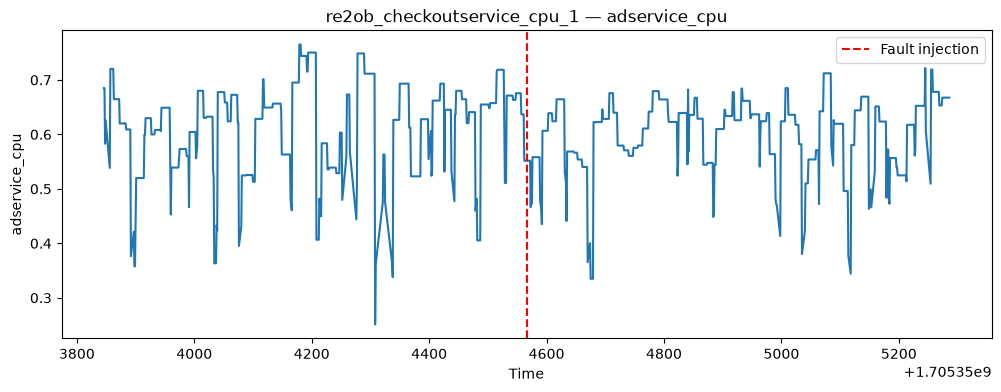

In [4]:
metric_columns = [
    column for column in metrics.columns
    if column != "time"
]

metric_column = metric_columns[0]

plt.figure(figsize=(12, 4))
plt.plot(metrics["time"], metrics[metric_column])
plt.axvline(
    inject_time,
    color="red",
    linestyle="--",
    label="Fault injection"
)

plt.title(f"{case['case']} — {metric_column}")
plt.xlabel("Time")
plt.ylabel(metric_column)
plt.legend()
plt.show()

In [5]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from RCAEval.utility import read_metrics


import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.run_deterministic_baseline import rank_metrics
from scripts.evaluate_results import evaluate_predictions

In [8]:
case = manifest.iloc[0]

case_dir = PROJECT_ROOT / Path(case["case_dir"])
metrics = read_metrics(case_dir)

metric_scores, service_scores = rank_metrics(
    metrics,
    inject_time=int(case["inject_time"])
)

display(service_scores)
display(metric_scores.head(10))

,service,score
0,checkoutservice,216.515964
1,emailservice,1.123984
2,currencyservice,0.916667
3,paymentservice,0.902699
4,productcatalogservice,0.765627
5,frontend,0.698139
6,cartservice,0.682083
7,redis,0.351786
8,shippingservice,0.178824
9,recommendationservice,0.160410


,metric,service,pre_mean,post_mean,delta,direction,score
0,checkoutservice_cpu,checkoutservice,4.303807e-01,1.808251e+01,1.765213e+01,increase,216.515964
1,checkoutservice_mem,checkoutservice,1.173056e+07,1.618168e+07,4.451123e+06,increase,22.454918
2,checkoutservice_socket,checkoutservice,9.000000e+00,1.095333e+01,1.953333e+00,increase,21.703704
3,emailservice_latency-90,emailservice,4.620823e-03,4.672760e-03,5.193730e-05,increase,1.123984
4,emailservice_latency-50,emailservice,3.011568e-03,3.040422e-03,2.885406e-05,increase,0.958107
5,currencyservice_socket,currencyservice,4.000000e+00,4.036667e+00,3.666667e-02,increase,0.916667
6,paymentservice_latency-50,paymentservice,3.546174e-03,3.732460e-03,1.862860e-04,increase,0.902699
7,checkoutservice_latency-50,checkoutservice,2.785185e-01,3.199212e-01,4.140269e-02,increase,0.840985
8,productcatalogservice_latency-50,productcatalogservice,2.139846e-03,2.062922e-03,-7.692424e-05,decrease,0.765627
9,currencyservice_latency-50,currencyservice,6.204636e-02,6.068479e-02,-1.361572e-03,decrease,0.728087


In [10]:
results = []

for _, case_row in manifest.iterrows():
    try:
        prediction = make_prediction(case_row)
        results.append(prediction)
    except Exception as exc:
        print(f"Failed on {case_row['case']}: {exc}")

In [11]:
results_dir = PROJECT_ROOT / "results" / "baselines"
results_dir.mkdir(parents=True, exist_ok=True)

prediction_path = results_dir / "deterministic_metric.jsonl"

with prediction_path.open("w") as f:
    for prediction in results:
        f.write(json.dumps(prediction) + "\n")

print(prediction_path)

/home/daniel/projects/RCAEval/results/baselines/deterministic_metric.jsonl


In [14]:
per_case, summary = evaluate_predictions(
    prediction_path,
    manifest
)

print(pd.Series(summary))
display(per_case.head())

num_cases          90.000000
AC@1                0.755556
AC@3                0.944444
AC@5                0.977778
MRR                 0.849815
mean_rank           1.566667
mean_tool_calls     0.000000
mean_replans        0.000000
dtype: float64


,case_id,true_service,predicted_top1,rank,AC@1,AC@3,AC@5,MRR,tool_calls,replans,latency_seconds,estimated_cost_usd
0,re2ob_checkoutservice_cpu_1,checkoutservice,checkoutservice,1,1,1,1,1.0,0,0,None,None
1,re2ob_currencyservice_cpu_2,currencyservice,currencyservice,1,1,1,1,1.0,0,0,None,None
2,re2ob_emailservice_cpu_2,emailservice,emailservice,1,1,1,1,1.0,0,0,None,None
3,re2ob_productcatalogservice_cpu_1,productcatalogservice,productcatalogservice,1,1,1,1,1.0,0,0,None,None
4,re2ob_recommendationservice_cpu_2,recommendationservice,recommendationservice,1,1,1,1,1.0,0,0,None,None


In [15]:
per_case = pd.read_csv(
    PROJECT_ROOT
    / "results/baselines/deterministic_metric_per_case.csv"
)

display(per_case.head())

In [16]:
print(manifest.columns.tolist())

['case', 'dataset', 'suite', 'system', 'system_name', 'root_cause_service', 'fault', 'fault_description', 'repetition', 'inject_time', 'n_metrics', 'n_timesteps', 'time_start', 'time_end', 'duration_minutes', 'normal_timesteps', 'faulty_timesteps', 'has_logs', 'n_logs', 'has_traces', 'n_traces', 'has_root_cause_file', 'case_dir', 'exists']
